# Viabilidad de un recomendador de perfumes mediante reglas de asociación

**Proyecto universitario · Análisis exploratorio y demostración reproducible**

Este notebook analiza el catálogo Parfumo incluido en data/parfumo_data_clean.csv. Cada fragancia consolidada representa una transacción y sus notas aromáticas representan los ítems. No se usan historiales de compra, usuarios ni transacciones comerciales.

Las reglas describen asociaciones estadísticas entre las notas de las fichas; no demuestran necesariamente que dos perfumes huelan parecido para una persona.

In [1]:
# Dependencias del análisis. En un entorno nuevo, esta celda las instala.
%pip install -q pandas numpy matplotlib mlxtend


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /tmp/perfumes-notebook-env/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import itertools
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

## 1. Introducción

El proyecto propone recomendar perfumes a partir de las notas aromáticas que aparecen juntas en sus fichas de producto. Cada perfume será una transacción y cada nota identificada será un ítem. No se utilizan usuarios, historiales de compra ni transacciones comerciales.

Apriori permite detectar conjuntos de notas que coaparecen con cierta frecuencia y reglas del tipo **vainilla + ámbar → almizcle**. Estas reglas describen asociaciones estadísticas en el catálogo; no demuestran que dos perfumes huelan parecido para una persona ni que una nota cause otra. La percepción olfativa deberá validarse con usuarios o especialistas.

El análisis caracteriza los datos reales, compara dos configuraciones de reglas y termina con una función que recomienda perfumes concretos presentes en el CSV.

## 2. Carga y exploración inicial

El CSV local de Parfumo se busca en data/ o, si el notebook se ejecuta desde su propia carpeta, en ../data/. Puedes cambiar la ruta en la celda siguiente. Primero inspeccionamos los campos reales antes de elegir las columnas de notas.

In [3]:
# Ruta configurable, con soporte para ejecutar desde la raíz o desde notebooks/.
rutas_candidatas = [Path("data/parfumo_data_clean.csv"), Path("../data/parfumo_data_clean.csv")]
RUTA_CSV = next((p for p in rutas_candidatas if p.exists()), rutas_candidatas[0])
if not RUTA_CSV.exists():
    raise FileNotFoundError(f"No se encontró {RUTA_CSV.resolve()}; edita RUTA_CSV para indicar la ubicación local.")

df = pd.read_csv(RUTA_CSV, low_memory=False)
print(f"Archivo cargado: {RUTA_CSV.as_posix()}")


def normalizar_texto(valor):
    """Normaliza etiquetas para comparar mayúsculas, acentos, signos y espacios."""
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if not unicodedata.combining(c)).casefold()
    texto = texto.replace("_", " ").replace("-", " ")
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def detectar_columna(aliases, fragmentos=()):
    normalizadas = {col: normalizar_texto(col) for col in df.columns}
    for alias in aliases:
        for col, nombre in normalizadas.items():
            if nombre == normalizar_texto(alias):
                return col
    for fragmento in fragmentos:
        for col, nombre in normalizadas.items():
            if normalizar_texto(fragmento) in nombre:
                return col
    return None


columna_marca = detectar_columna(["brand", "brand name", "marca"], ["brand", "marca"])
columna_nombre = detectar_columna(
    ["name", "product name", "perfume name", "nombre", "title"],
    ["product name", "perfume name", "nombre", "name", "title"],
)
columna_concentracion = detectar_columna(
    ["concentration", "concentracion"], ["concentration", "concentracion"]
)
columna_url = detectar_columna(["url", "product url", "link"], ["url"])

print("Primeras diez filas del archivo original")
display(df.head(10))
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")

Archivo cargado: data/parfumo_data_clean.csv
Primeras diez filas del archivo original


,Number,Name,Brand,Release_Year,Concentration,Rating_Value,Rating_Count,Main_Accords,Top_Notes,Middle_Notes,Base_Notes,Perfumers,URL
0,455,Tabac Écarlate,Le Ré Noir,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Valery Sokolov / Валерий Соколов,https://www.parfumo.com/Perfumes/Le_Re_Noir/455-tabac-ecarlate
1,0071,Tidal Pool,CB I Hate Perfume,2004.0,NaN,NaN,NaN,NaN,Bergamot,French lavender,"Musk, Foulness",Harry Frémont,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/0071_Tidal_Pool
2,0154,Pumpkin Pie,CB I Hate Perfume,1998.0,NaN,NaN,NaN,"Green, Leathery, Chypre, Animal",NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/0154_Pumpkin_Pie
3,0162,Wet Stone,CB I Hate Perfume,2006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/0162_Wet_Stone
4,0171,Chocolate Box,CB I Hate Perfume,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/0171-chocolate-box
5,0191,My Birthday Cake,CB I Hate Perfume,1975.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/0191-my-birthday-cake
6,02,Coco.Conut,W.Dressroom,NaN,NaN,NaN,NaN,NaN,Coconut,"Milk, Tonka bean","Amber, Musk, Vanilla",NaN,https://www.parfumo.com/Perfumes/W_Dressroom/02__Coco_Conut
7,03,Baby Green Tea,W.Dressroom,NaN,NaN,NaN,NaN,NaN,"Basil, Bergamot, Lemon, Orange","Iris, Jasmine, Lily of the valley, Orchid, Rose","Amber, Musk",NaN,https://www.parfumo.com/Perfumes/W_Dressroom/03-baby-green-tea
8,047,Beautiful Launderette,CB I Hate Perfume,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/Beautiful_Launderette
9,069,Wet Pavement London,CB I Hate Perfume,NaN,NaN,NaN,NaN,NaN,"Aquatic notes, Lemon, Tangerine, Charcoal","Amber, Cedarwood, Floral notes, Acridity","Leather, Oakmoss, Patchouli, Tonka bean, Sewer",NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Perfume/069_Wet_Pavement_London


Dimensiones: 59,325 filas × 13 columnas


In [4]:
print("Columnas y tipos de datos")
display(pd.DataFrame({"Columna": df.columns, "Tipo": [str(tipo) for tipo in df.dtypes]}))

# Se cuentan NaN y cadenas vacías como faltantes informativos.
blancos = pd.Series(0, index=df.columns, dtype="int64")
for col in df.select_dtypes(include=["object", "string"]).columns:
    blancos[col] = df[col].astype("string").str.strip().eq("").fillna(False).sum()
faltantes = df.isna().sum() + blancos
print("Valores nulos o vacíos por columna")
display(pd.DataFrame({
    "Columna": df.columns,
    "Cantidad": faltantes.values,
    "Porcentaje (%)": (faltantes.values / max(len(df), 1) * 100).round(2),
}))

print(f"Filas completamente duplicadas: {int(df.duplicated().sum()):,}")
if columna_marca is not None:
    marcas = df[columna_marca].dropna().astype(str).str.strip()
    print(f"Marcas únicas en {columna_marca!r}: {marcas[marcas.ne('')].nunique():,}")
else:
    print("No se identificó automáticamente una columna de marca.")
if columna_nombre is not None:
    nombres = df[columna_nombre].dropna().astype(str).str.strip()
    print(f"Nombres de perfume únicos en {columna_nombre!r}: {nombres[nombres.ne('')].nunique():,}")
    if columna_marca is not None:
        print(f"Combinaciones marca + nombre distintas: {df[[columna_marca, columna_nombre]].dropna().drop_duplicates().shape[0]:,}")
else:
    print("No se identificó automáticamente una columna de nombre de perfume.")

Columnas y tipos de datos


,Columna,Tipo
0,Number,str
1,Name,str
2,Brand,str
3,Release_Year,float64
4,Concentration,str
5,Rating_Value,float64
6,Rating_Count,float64
7,Main_Accords,str
8,Top_Notes,str
9,Middle_Notes,str


Valores nulos o vacíos por columna


,Columna,Cantidad,Porcentaje (%)
0,Number,57905,97.61
1,Name,1,0.00
2,Brand,1,0.00
3,Release_Year,20316,34.25
4,Concentration,46842,78.96
5,Rating_Value,29279,49.35
6,Rating_Count,29279,49.35
7,Main_Accords,27100,45.68
8,Top_Notes,28186,47.51
9,Middle_Notes,28176,47.49


Filas completamente duplicadas: 9


Marcas únicas en 'Brand': 1,451
Nombres de perfume únicos en 'Name': 55,119
Combinaciones marca + nombre distintas: 58,825


Las filas anteriores corresponden al CSV tal como se recibió. En este archivo hay cabeceras repetidas dentro de los datos y publicaciones/variantes repetidas. Se detectarán antes del análisis. Para no sobreponderar una fragancia, el catálogo consolidará por marca y nombre base (retirando un sufijo de concentración cuando está escrito en el título), conservando la ficha que tenga más notas utilizables sin fusionar listas de variantes.

## 3. Análisis de notas aromáticas

Se detectan campos cuyo nombre indica notas (`note`, `notes`, `nota` o `notas`) y se clasifican, si es posible, como salida, corazón o fondo. Campos de familias o acordes como `scents` se informan por separado y no se mezclan con notas individuales.

In [5]:
columnas_notas = []
for col in df.columns:
    tokens = set(normalizar_texto(col).split())
    if tokens & {"note", "notes", "nota", "notas"} and not tokens & {"rating", "score", "count", "review", "reviews"}:
        columnas_notas.append(col)


def clasificar_etapa(col):
    tokens = set(normalizar_texto(col).split())
    if tokens & {"top", "head", "salida"}:
        return "Salida"
    if tokens & {"heart", "middle", "mid", "corazon"}:
        return "Corazón"
    if tokens & {"base", "fondo"}:
        return "Fondo"
    return "General"


columnas_acordes = []
for col in df.columns:
    if set(normalizar_texto(col).split()) & {"scent", "scents", "accord", "accords", "acorde", "acordes"}:
        columnas_acordes.append(col)
if columnas_notas:
    display(pd.DataFrame({"Columna de notas": columnas_notas, "Etapa interpretada": [clasificar_etapa(c) for c in columnas_notas]}))
else:
    print("No se detectaron columnas de notas por su nombre.")
print("Campos aromáticos excluidos por ser familias/acordes:", columnas_acordes if columnas_acordes else "ninguno")
etapas_presentes = {clasificar_etapa(c) for c in columnas_notas}
for etapa in ["Salida", "Corazón", "Fondo"]:
    if etapa not in etapas_presentes:
        print(f"No se identificó una columna de notas de {etapa.lower()}.")

,Columna de notas,Etapa interpretada
0,Top_Notes,Salida
1,Middle_Notes,Corazón
2,Base_Notes,Fondo


Campos aromáticos excluidos por ser familias/acordes: ['Main_Accords']


In [6]:
AUSENTES_TEXTO = {
    "", "na", "n a", "nan", "none", "null", "nil", "unknown",
    "not available", "not specified", "no data", "-", "--",
}


def separar_notas(celda):
    """Separa delimitadores comunes y conserva nombres compuestos."""
    if pd.isna(celda):
        return []
    texto = unicodedata.normalize("NFKC", str(celda)).strip()
    if normalizar_texto(texto) in AUSENTES_TEXTO:
        return []
    resultado = []
    # No dividir por espacios, conjunciones, ampersands o barras.
    for parte in re.split(r"[,;|\n\r•·]+", texto):
        nota = normalizar_texto(parte)
        if nota and nota not in AUSENTES_TEXTO:
            resultado.append(nota)
    return list(dict.fromkeys(resultado))


NOTAS = "__notas_normalizadas__"
FILA = "__fila_origen__"
CLAVE = "__clave_producto__"
CLAVE_FRAGANCIA = "__clave_fragancia__"

filas_archivo = df.copy()
filas_archivo[FILA] = np.arange(len(filas_archivo), dtype=int)
columnas_cabecera = [c for c in [columna_nombre, columna_marca, columna_url] if c is not None]
mascara_cabecera = pd.Series(True, index=filas_archivo.index)
if len(columnas_cabecera) >= 2:
    for col in columnas_cabecera:
        mascara_cabecera &= filas_archivo[col].map(normalizar_texto).eq(normalizar_texto(col))
else:
    mascara_cabecera[:] = False
numero_cabeceras_incrustadas = int(mascara_cabecera.sum())
filas = filas_archivo.loc[~mascara_cabecera].copy()

if columnas_notas:
    filas[NOTAS] = filas[columnas_notas].apply(
        lambda fila: list(dict.fromkeys(
            n for col in columnas_notas for n in separar_notas(fila[col])
        )),
        axis=1,
    )
else:
    filas[NOTAS] = [[] for _ in range(len(filas))]
filas["__cantidad_notas__"] = filas[NOTAS].map(len)


def normalizar_url(valor):
    return "" if pd.isna(valor) else str(valor).strip().casefold().rstrip("/")


if columna_url is not None:
    filas["__url_normalizada__"] = filas[columna_url].map(normalizar_url)
    urls = filas.loc[filas["__url_normalizada__"].ne(""), "__url_normalizada__"]
    filas_repetidas_url = int(len(urls) - urls.nunique())
    filas["__clave_url__"] = filas.apply(
        lambda r: ("url", r["__url_normalizada__"]) if r["__url_normalizada__"]
        else ("fila", int(r[FILA])), axis=1,
    )
else:
    filas["__url_normalizada__"] = ""
    filas_repetidas_url = 0
    filas["__clave_url__"] = [("fila", int(i)) for i in filas[FILA]]

filas_sin_url_repetida = (
    filas.sort_values(["__cantidad_notas__", FILA], ascending=[False, True])
    .drop_duplicates("__clave_url__", keep="first")
    .sort_values(FILA).copy()
)


concentraciones_observadas = []
if columna_concentracion is not None:
    concentraciones_observadas = sorted(
        {normalizar_texto(v) for v in filas[columna_concentracion].dropna() if normalizar_texto(v)},
        key=len,
        reverse=True,
    )


def nombre_base(fila):
    nombre = normalizar_texto(fila[columna_nombre]) if columna_nombre else ""
    if not nombre:
        return ""
    concentracion = (
        normalizar_texto(fila[columna_concentracion])
        if columna_concentracion is not None else ""
    )
    sufijos = ([concentracion] if concentracion else []) + [
        s for s in concentraciones_observadas if s != concentracion
    ]
    for sufijo in sufijos:
        if sufijo and nombre.endswith(" " + sufijo):
            base = nombre[:-(len(sufijo) + 1)].strip()
            if base:
                return base
    return nombre


def clave_producto(fila):
    marca = normalizar_texto(fila[columna_marca]) if columna_marca else ""
    nombre = nombre_base(fila)
    if marca and nombre:
        return ("marca_nombre", marca, nombre)
    if fila["__url_normalizada__"]:
        return ("url", fila["__url_normalizada__"])
    return ("fila", int(fila[FILA]))


filas_sin_url_repetida[CLAVE] = filas_sin_url_repetida.apply(clave_producto, axis=1)
repeticiones_identidad = filas_sin_url_repetida[CLAVE].value_counts()
grupos_identidad_repetidos = int((repeticiones_identidad > 1).sum())
catalogo = (
    filas_sin_url_repetida
    .sort_values(["__cantidad_notas__", FILA], ascending=[False, True])
    .drop_duplicates(CLAVE, keep="first")
    .sort_values(FILA).reset_index(drop=True)
)
filas_variantes_consolidadas = len(filas_sin_url_repetida) - len(catalogo)
filas_consolidadas = len(filas) - len(catalogo)
catalogo["id_perfume"] = np.arange(len(catalogo), dtype=int)


def valor_legible(fila, col, alternativo):
    if col is None or pd.isna(fila[col]) or not str(fila[col]).strip():
        return alternativo
    return str(fila[col]).strip()


catalogo["marca_mostrada"] = catalogo.apply(
    lambda r: valor_legible(r, columna_marca, "Marca no identificada"), axis=1
)
catalogo["nombre_mostrado"] = catalogo.apply(
    lambda r: valor_legible(r, columna_nombre, f"Registro {int(r[FILA])}"), axis=1
)
catalogo["concentracion_mostrada"] = catalogo.apply(
    lambda r: valor_legible(r, columna_concentracion, ""), axis=1
)
catalogo["etiqueta_perfume"] = catalogo.apply(
    lambda r: " — ".join(
        x for x in [r["marca_mostrada"], r["nombre_mostrado"], r["concentracion_mostrada"]] if x
    ) + f" (ID {r['id_perfume']})",
    axis=1,
)
catalogo[CLAVE_FRAGANCIA] = catalogo[CLAVE]

print(f"Cabeceras incrustadas excluidas: {numero_cabeceras_incrustadas:,}")
print(f"Filas exactamente duplicadas en el CSV original: {int(df.duplicated().sum()):,}")
print(f"Filas repetidas por URL colapsadas: {filas_repetidas_url:,}")
print(f"Variantes/publicaciones adicionales por marca + nombre base: {filas_variantes_consolidadas:,}")
print(f"Filas consolidadas en total: {filas_consolidadas:,}")
print(f"Catálogo analítico: {len(catalogo):,} perfumes.")
print("La identidad usa marca + nombre base y retira sufijos de concentración observados en el CSV.")
print("Se conserva la ficha más completa; no se mezclan sus notas.")

Cabeceras incrustadas excluidas: 10
Filas exactamente duplicadas en el CSV original: 9
Filas repetidas por URL colapsadas: 35
Variantes/publicaciones adicionales por marca + nombre base: 4,162
Filas consolidadas en total: 4,197
Catálogo analítico: 55,118 perfumes.
La identidad usa marca + nombre base y retira sufijos de concentración observados en el CSV.
Se conserva la ficha más completa; no se mezclan sus notas.


La normalización pasa las etiquetas a minúsculas, uniforma acentos, guiones y espacios, y descarta valores ausentes. Se separa por comas, punto y coma, barra vertical, saltos de línea y viñetas. No se parte por espacios, conjunciones, ampersands ni barras para proteger nombres compuestos como “lily of the valley”. No se inventan notas ni sinónimos.

Se eliminan las cabeceras incrustadas y se deduplican URLs. Después se agrupan fichas por marca y nombre base. Si una concentración observada aparece como sufijo del nombre, se retira para identificar variantes de la misma fragancia; la concentración no se usa sola como identidad porque ese campo está muy incompleto. En caso de varias fichas, se conserva la que contiene más notas; no se combinan sus listas. La cobertura se calcula sobre el catálogo consolidado. Las reglas usan solo perfumes con notas: un campo vacío representa información desconocida, no ausencia confirmada de notas.

Resumen de notas


,Medida,Resultado
0,Filas originales con notas,"31,162 de 59,315 (52.5%)"
1,Perfumes consolidados con notas,"28,595 de 55,118 (51.9%)"
2,Perfumes sin notas utilizables,"26,523"
3,Notas aromáticas únicas,"3,981"
4,Promedio de notas por perfume (incluye ceros),5.23
5,Mediana de notas por perfume (incluye ceros),4.00
6,Promedio entre perfumes con notas,10.07
7,Mediana entre perfumes con notas,9.00


20 notas más frecuentes


,Nota,Perfumes
0,musk,12683
1,bergamot,9768
2,sandalwood,9440
3,jasmine,8626
4,vanilla,8558
5,amber,8522
6,patchouli,8363
7,rose,6929
8,mandarin orange,4693
9,vetiver,4627


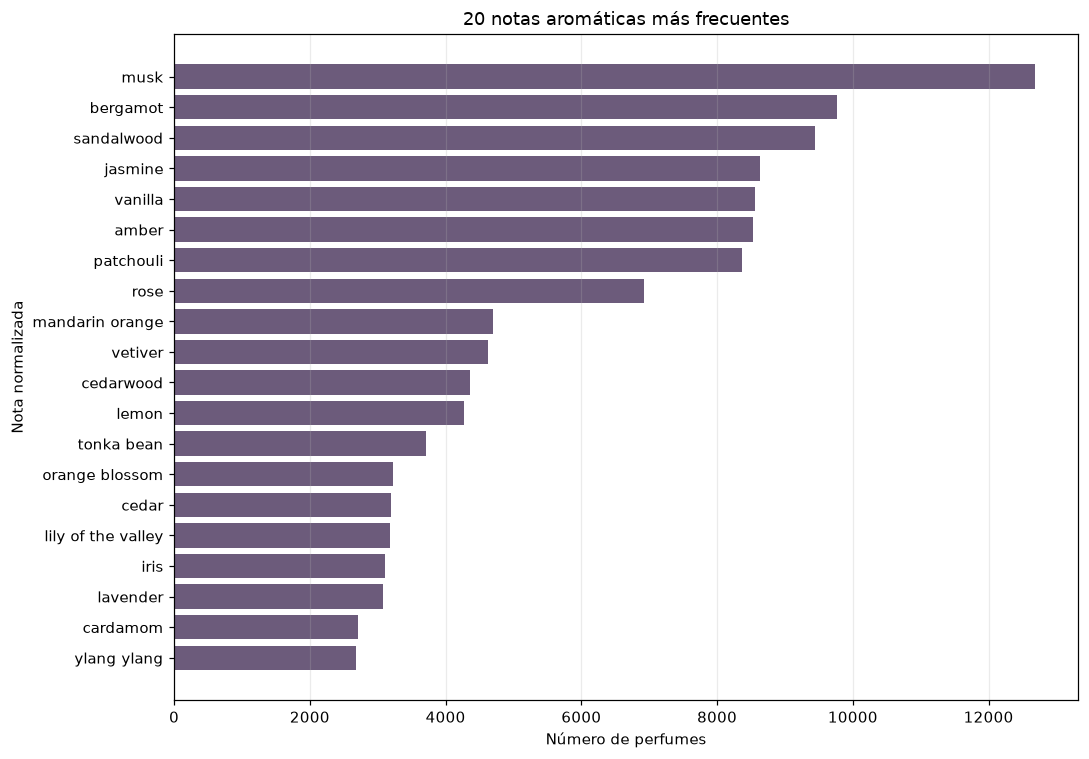

Combinaciones de dos notas más frecuentes


,Par de notas,Perfumes
0,bergamot + musk,4978
1,musk + sandalwood,4834
2,jasmine + musk,4704
3,amber + musk,4546
4,bergamot + sandalwood,3996
5,musk + vanilla,3988
6,musk + rose,3840
7,bergamot + jasmine,3702
8,jasmine + sandalwood,3654
9,bergamot + patchouli,3647


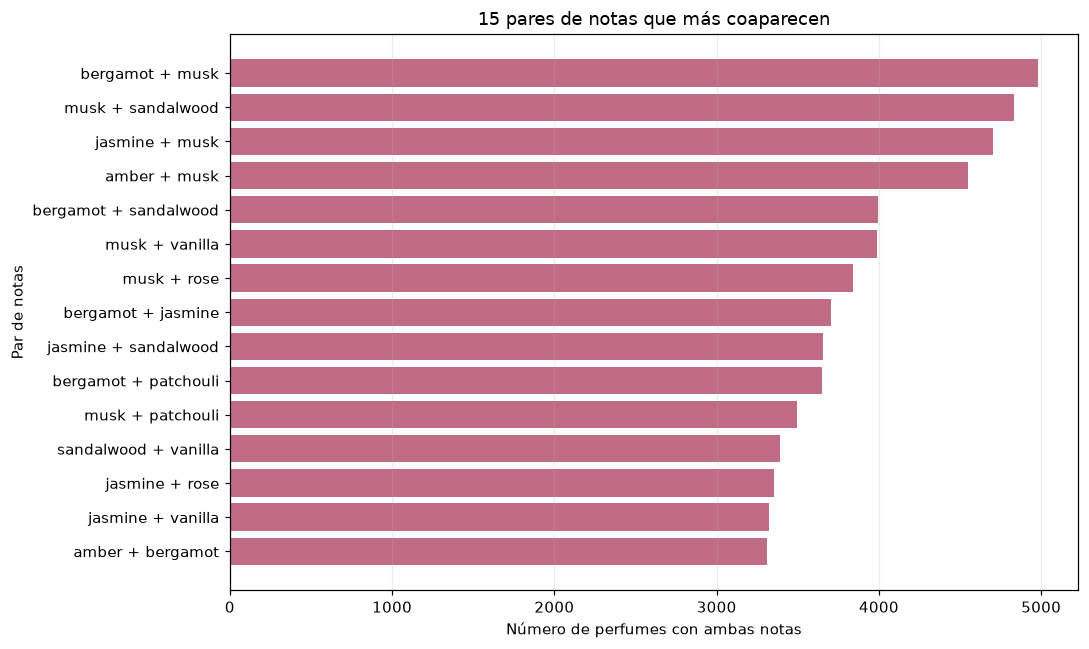

In [7]:
notas_por_perfume = catalogo[NOTAS].tolist()
numero_catalogo = len(catalogo)
numero_con_notas = int(catalogo[NOTAS].map(bool).sum())
numero_sin_notas = numero_catalogo - numero_con_notas
porcentaje_con_notas = numero_con_notas / numero_catalogo * 100 if numero_catalogo else 0.0
numero_filas_con_notas = int(filas[NOTAS].map(bool).sum())
porcentaje_filas_con_notas = numero_filas_con_notas / len(filas) * 100 if len(filas) else 0.0
notas_unicas = sorted({nota for transaccion in notas_por_perfume for nota in transaccion})
frecuencia_notas = Counter(n for transaccion in notas_por_perfume for n in set(transaccion))
frecuencia_pares = Counter(
    par for transaccion in notas_por_perfume
    for par in itertools.combinations(sorted(set(transaccion)), 2)
)
cantidades = pd.Series([len(t) for t in notas_por_perfume], dtype="int64")
cantidades_con_notas = cantidades[cantidades > 0]

print("Resumen de notas")
display(pd.DataFrame([
    {"Medida": "Filas originales con notas", "Resultado": f"{numero_filas_con_notas:,} de {len(filas):,} ({porcentaje_filas_con_notas:.1f}%)"},
    {"Medida": "Perfumes consolidados con notas", "Resultado": f"{numero_con_notas:,} de {numero_catalogo:,} ({porcentaje_con_notas:.1f}%)"},
    {"Medida": "Perfumes sin notas utilizables", "Resultado": f"{numero_sin_notas:,}"},
    {"Medida": "Notas aromáticas únicas", "Resultado": f"{len(notas_unicas):,}"},
    {"Medida": "Promedio de notas por perfume (incluye ceros)", "Resultado": f"{cantidades.mean():.2f}" if len(cantidades) else "No calculable"},
    {"Medida": "Mediana de notas por perfume (incluye ceros)", "Resultado": f"{cantidades.median():.2f}" if len(cantidades) else "No calculable"},
    {"Medida": "Promedio entre perfumes con notas", "Resultado": f"{cantidades_con_notas.mean():.2f}" if len(cantidades_con_notas) else "No calculable"},
    {"Medida": "Mediana entre perfumes con notas", "Resultado": f"{cantidades_con_notas.median():.2f}" if len(cantidades_con_notas) else "No calculable"},
]))

top_notas = pd.DataFrame(frecuencia_notas.most_common(20), columns=["Nota", "Perfumes"])
print("20 notas más frecuentes")
display(top_notas)
if not top_notas.empty:
    g = top_notas.sort_values("Perfumes")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(g["Nota"], g["Perfumes"], color="#6C5B7B")
    ax.set(title="20 notas aromáticas más frecuentes", xlabel="Número de perfumes", ylabel="Nota normalizada")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout(); plt.show()

pares_top = pd.DataFrame([(f"{a} + {b}", n) for (a, b), n in frecuencia_pares.most_common(20)], columns=["Par de notas", "Perfumes"])
print("Combinaciones de dos notas más frecuentes")
display(pares_top)
if not pares_top.empty:
    g = pares_top.head(15).sort_values("Perfumes")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(g["Par de notas"], g["Perfumes"], color="#C06C84")
    ax.set(title="15 pares de notas que más coaparecen", xlabel="Número de perfumes con ambas notas", ylabel="Par de notas")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout(); plt.show()

## 4. Preparación de transacciones

Cada perfume consolidado con al menos una nota forma una transacción independiente. Las notas repetidas dentro de una ficha se eliminan. Los perfumes sin notas permanecen en el catálogo para calcular la cobertura, pero no se incorporan al minero como transacciones vacías: la falta de datos no demuestra ausencia de notas.

La matriz se codifica en formato disperso, más eficiente para un catálogo en el que la mayoría de las notas no aparece en cada perfume.

In [8]:
catalogo_modelo = catalogo[catalogo[NOTAS].map(bool)].copy()
transacciones = [list(dict.fromkeys(notas)) for notas in catalogo_modelo[NOTAS]]
print(f"Transacciones con notas: {len(transacciones):,}")
print(f"Perfumes sin notas utilizables, excluidos del minero: {len(catalogo) - len(catalogo_modelo):,}")

print("Ejemplos antes de codificar")
muestra = catalogo_modelo[
    ["id_perfume", "marca_mostrada", "nombre_mostrado", NOTAS]
].head(5).copy()
muestra.columns = ["ID", "Marca", "Perfume", "Notas de la transacción"]
display(muestra)

if transacciones:
    codificador = TransactionEncoder()
    arreglo = codificador.fit(transacciones).transform(transacciones, sparse=True)
    matriz_transacciones = pd.DataFrame.sparse.from_spmatrix(
        arreglo, columns=codificador.columns_, index=catalogo_modelo["id_perfume"]
    )
    matriz_transacciones.index.name = "ID_perfume"
    print(
        f"Matriz binaria dispersa: {matriz_transacciones.shape[0]:,} transacciones "
        f"× {matriz_transacciones.shape[1]:,} notas."
    )
    vista = pd.DataFrame(
        arreglo[:5, :12].toarray(),
        columns=codificador.columns_[:12],
        index=catalogo_modelo["id_perfume"].head(5),
    )
    vista.index.name = "ID_perfume"
    print("True indica que la nota aparece en la transacción.")
    display(vista)
else:
    matriz_transacciones = pd.DataFrame(index=catalogo_modelo["id_perfume"])
    matriz_transacciones.index.name = "ID_perfume"
    print("No hay notas utilizables para construir una matriz de ítems.")

Transacciones con notas: 28,595
Perfumes sin notas utilizables, excluidos del minero: 26,523
Ejemplos antes de codificar


,ID,Marca,Perfume,Notas de la transacción
1,1,CB I Hate Perfume,Tidal Pool,"[bergamot, french lavender, musk, foulness]"
6,6,W.Dressroom,Coco.Conut,"[coconut, milk, tonka bean, amber, musk, vanilla]"
7,7,W.Dressroom,Baby Green Tea,"[basil, bergamot, lemon, orange, iris, jasmine, lily of the valley, orchid, rose, amber, musk]"
9,9,CB I Hate Perfume,Wet Pavement London,"[aquatic notes, lemon, tangerine, charcoal, amber, cedarwood, floral notes, acridity, leather, oakmoss, patchouli, t..."
10,10,W.Dressroom,Gogo Mango,"[mango, orange, peach, jasmine, rose, balsam, musk]"


Matriz binaria dispersa: 28,595 transacciones × 3,981 notas.
True indica que la nota aparece en la transacción.


,2 methylundecanal,abelmoschus,abrialis lavender,absinth,absinthe wormwood,acacia,acacia honey,acacia honey absolute,acacia leaf,acacia wood,acai,acajou wood
ID_perfume,,,,,,,,,,,,
1,False,False,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False,False,False,False,False
10,False,False,False,False,False,False,False,False,False,False,False,False


## 5. Reglas de asociación con Apriori

- **Soporte:** porcentaje y cantidad aproximada de perfumes que contienen juntas las notas de la regla.
- **Confianza:** entre los perfumes que contienen el antecedente, proporción que también tiene el consecuente.
- **Lift:** compara la confianza con la frecuencia esperada del consecuente sin asociación. Un lift mayor que 1 indica coocurrencia positiva en este catálogo, pero no garantiza utilidad.

Se comparan dos configuraciones con denominador igual al número de perfumes que sí tienen notas: A usa soporte mínimo max(10/N, 1%) y confianza 0,35; B usa max(30/N, 3%) y confianza 0,55. Apriori se limita a conjuntos de hasta tres notas. Si no aparecen asociaciones positivas, se prueba soporte max(2/N, 0,5%) y confianza 0,25.

El soporte cuenta recurrencias descriptivas del catálogo; no es una prueba de significancia ni evidencia de preferencia de consumidores.

In [9]:
n_transacciones = len(catalogo_modelo)
if n_transacciones:
    soporte_A = min(1.0, max(10 / n_transacciones, 0.01))
    soporte_B = min(1.0, max(30 / n_transacciones, 0.03))
    soporte_ajustado = min(1.0, max(2 / n_transacciones, 0.005))
else:
    soporte_A = soporte_B = soporte_ajustado = 1.0


def ejecutar_configuracion(nombre, soporte, confianza):
    vacio = pd.DataFrame()
    if matriz_transacciones.empty or matriz_transacciones.shape[1] == 0 or not n_transacciones:
        return {"nombre": nombre, "soporte": soporte, "confianza": confianza,
                "itemsets": vacio, "reglas": vacio}
    itemsets = apriori(
        matriz_transacciones, min_support=soporte, use_colnames=True,
        max_len=3, low_memory=True,
    )
    if itemsets.empty or not itemsets["itemsets"].map(len).ge(2).any():
        reglas = vacio
    else:
        reglas = association_rules(
            itemsets, metric="confidence", min_threshold=confianza,
            num_itemsets=n_transacciones,
        )
        if not reglas.empty:
            reglas = reglas.replace([np.inf, -np.inf], np.nan).dropna(
                subset=["support", "confidence", "lift"]
            ).copy()
            reglas["perfumes_respaldo"] = np.rint(
                reglas["support"] * n_transacciones
            ).astype(int)
    return {"nombre": nombre, "soporte": soporte, "confianza": confianza,
            "itemsets": itemsets, "reglas": reglas}


resultados = [
    ejecutar_configuracion("A · exploratoria", soporte_A, 0.35),
    ejecutar_configuracion("B · más estricta", soporte_B, 0.55),
]


def tiene_regla_positiva(resultado):
    return not resultado["reglas"].empty and bool((resultado["reglas"]["lift"] > 1).any())


if not any(tiene_regla_positiva(r) for r in resultados):
    resultados.append(
        ejecutar_configuracion("C · ajuste justificado", soporte_ajustado, 0.25)
    )

resumen_config = pd.DataFrame([{
    "Configuración": r["nombre"],
    "Soporte mínimo": r["soporte"],
    "Confianza mínima": r["confianza"],
    "Conjuntos frecuentes": len(r["itemsets"]),
    "Reglas generadas": len(r["reglas"]),
    "Perfumes mínimos por soporte": int(np.ceil(r["soporte"] * n_transacciones))
    if n_transacciones else 0,
} for r in resultados])
print(f"Perfumes con notas usados como denominador: {n_transacciones:,}")
print("Comparación de configuraciones")
display(resumen_config)

primario = next(
    (r for r in resultados if r["nombre"] == "B · más estricta" and tiene_regla_positiva(r)),
    None,
)
if primario is None:
    primario = next(
        (r for r in resultados if r["nombre"] == "A · exploratoria" and tiene_regla_positiva(r)),
        None,
    )
if primario is None:
    primario = next(
        (r for r in resultados if r["nombre"] == "C · ajuste justificado" and tiene_regla_positiva(r)),
        None,
    )
if primario is None:
    primario = resultados[-1]
    reglas_modelo = pd.DataFrame()
    print("No se encontraron reglas con lift > 1 en las configuraciones ejecutadas.")
else:
    reglas_modelo = primario["reglas"].copy()
    reglas_modelo = reglas_modelo[
        (reglas_modelo["lift"] > 1) & (reglas_modelo["perfumes_respaldo"] >= 2)
    ].copy()
    print(
        f"Configuración elegida: {primario['nombre']}; "
        f"conjuntos frecuentes: {len(primario['itemsets']):,}; "
        f"reglas candidatas: {len(reglas_modelo):,}."
    )

Perfumes con notas usados como denominador: 28,595
Comparación de configuraciones


,Configuración,Soporte mínimo,Confianza mínima,Conjuntos frecuentes,Reglas generadas,Perfumes mínimos por soporte
0,A · exploratoria,0.01,0.35,1881,2021,286
1,B · más estricta,0.03,0.55,310,45,858


Configuración elegida: B · más estricta; conjuntos frecuentes: 310; reglas candidatas: 45.


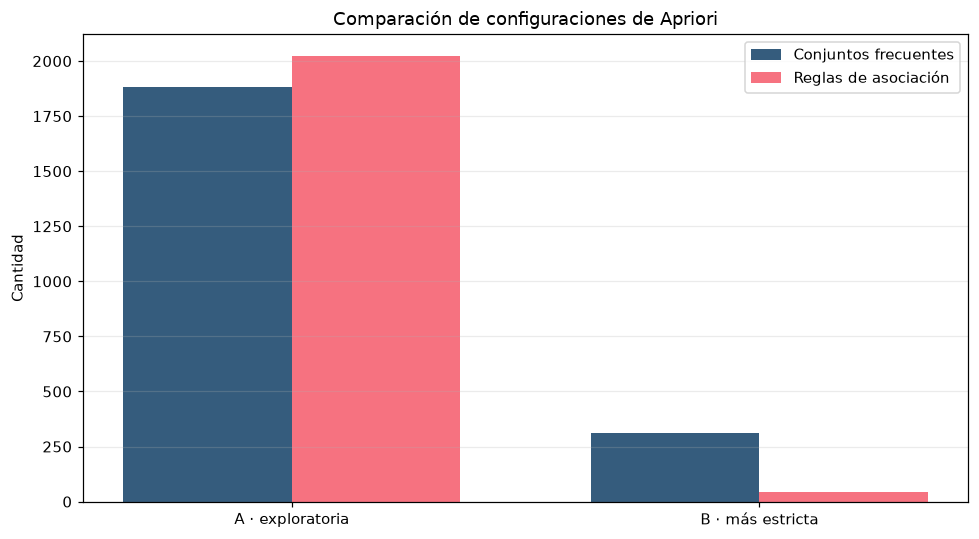

Reglas destacadas por lift y soporte


,Regla,Soporte (%),Confianza (%),Lift,Perfumes de respaldo (aprox.)
0,jasmine + lily of the valley → rose,3.22,55.19,2.278,920
1,lily of the valley + rose → jasmine,3.22,66.14,2.193,920
2,bergamot + lily of the valley → jasmine,3.06,63.66,2.110,876
3,lily of the valley + sandalwood → jasmine,3.20,61.98,2.054,916
4,bergamot + rose → jasmine,5.93,59.54,1.974,1697
5,rose + sandalwood → jasmine,5.84,56.85,1.884,1669
6,lily of the valley + musk → jasmine,3.90,55.61,1.843,1116
7,jasmine + lemon → bergamot,3.64,62.96,1.843,1042
8,lemon + sandalwood → bergamot,3.61,62.70,1.835,1032
9,lemon + patchouli → bergamot,3.40,62.32,1.824,971


Reglas con mayor soporte; el conteo de perfumes permite valorar su frecuencia


,Regla,Soporte (%),Confianza (%),Lift,Perfumes de respaldo (aprox.)
0,rose → musk,13.43,55.42,1.249,3840
1,bergamot + sandalwood → musk,8.00,57.28,1.291,2289
2,bergamot + jasmine → musk,7.78,60.10,1.355,2225
3,jasmine + sandalwood → musk,7.48,58.57,1.320,2140
4,jasmine + rose → musk,7.26,61.86,1.395,2076
5,amber + jasmine → musk,7.11,63.87,1.440,2033
6,amber + bergamot → musk,7.05,60.89,1.373,2016
7,lily of the valley → musk,7.02,63.11,1.423,2007
8,amber + sandalwood → musk,6.89,60.19,1.357,1970
9,rose + sandalwood → musk,6.14,59.78,1.348,1755


Un lift alto con pocos perfumes de respaldo debe interpretarse con cautela.


In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(resumen_config)); ancho = 0.36
ax.bar(x - ancho/2, resumen_config["Conjuntos frecuentes"], ancho, label="Conjuntos frecuentes", color="#355C7D")
ax.bar(x + ancho/2, resumen_config["Reglas generadas"], ancho, label="Reglas de asociación", color="#F67280")
ax.set_xticks(x, resumen_config["Configuración"])
ax.set_ylabel("Cantidad")
ax.set_title("Comparación de configuraciones de Apriori")
ax.legend(); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()


def texto_itemset(itemset):
    return " + ".join(sorted(map(str, itemset)))


def tabla_reglas(reglas, ordenar="lift", cantidad=12):
    if reglas.empty:
        return pd.DataFrame()
    ordenadas = reglas.sort_values([ordenar, "support", "confidence"], ascending=False).head(cantidad)
    return pd.DataFrame({
        "Regla": [f"{texto_itemset(a)} → {texto_itemset(c)}" for a, c in zip(ordenadas["antecedents"], ordenadas["consequents"])],
        "Soporte (%)": (ordenadas["support"].to_numpy() * 100).round(2),
        "Confianza (%)": (ordenadas["confidence"].to_numpy() * 100).round(2),
        "Lift": ordenadas["lift"].round(3).to_numpy(),
        "Perfumes de respaldo (aprox.)": ordenadas["perfumes_respaldo"].to_numpy(),
    })


if not reglas_modelo.empty:
    print("Reglas destacadas por lift y soporte")
    display(tabla_reglas(reglas_modelo, "lift", 15))
    print("Reglas con mayor soporte; el conteo de perfumes permite valorar su frecuencia")
    display(tabla_reglas(reglas_modelo, "support", 10))
    print("Un lift alto con pocos perfumes de respaldo debe interpretarse con cautela.")
else:
    print("No hay reglas candidatas para listar; revisa cobertura y umbrales.")

## 6. Demostración de recomendaciones

La función recomendar_perfumes() acepta el ID, la etiqueta o un nombre inequívoco de una fragancia. Recupera sus notas, aplica reglas cuyo antecedente está presente y busca otros perfumes que contienen el patrón completo de la regla.

Se excluye el perfume seleccionado y se deduplican fichas por marca y nombre. Los candidatos se ordenan por lift, soporte y confianza de la regla; la similitud de Jaccard sirve solo como desempate. La salida muestra notas compartidas, notas asociadas nuevas, regla justificante y respaldo aproximado.

In [11]:
catalogo["__conjunto_notas__"] = catalogo[NOTAS].map(set)
notas_por_id = {
    int(i): set(notas) for i, notas in zip(catalogo["id_perfume"], catalogo[NOTAS])
}
clave_fragancia_por_id = {
    int(i): k for i, k in zip(catalogo["id_perfume"], catalogo[CLAVE_FRAGANCIA])
}
fila_por_id = catalogo.set_index("id_perfume", drop=False)

# Índice invertido: nota -> IDs de perfumes que la contienen.
indice_nota = {}
for id_perfume, notas in notas_por_id.items():
    for nota in notas:
        indice_nota.setdefault(nota, set()).add(id_perfume)
_cache_intersecciones = {}


def ids_con_notas(conjunto):
    clave_cache = frozenset(conjunto)
    if clave_cache not in _cache_intersecciones:
        if not clave_cache:
            resultado = set()
        else:
            listas = [indice_nota.get(n, set()) for n in clave_cache]
            if any(not lista for lista in listas):
                resultado = set()
            else:
                listas.sort(key=len)
                resultado = set(listas[0])
                for lista in listas[1:]:
                    resultado.intersection_update(lista)
                    if not resultado:
                        break
        _cache_intersecciones[clave_cache] = resultado
    return _cache_intersecciones[clave_cache]


reglas_recomendacion = []
ids_recomendables = set()
if not reglas_modelo.empty:
    for r in reglas_modelo.itertuples(index=False):
        antecedente, consecuente = set(r.antecedents), set(r.consequents)
        respaldo = int(round(float(r.support) * n_transacciones))
        if float(r.lift) <= 1 or respaldo < 2:
            continue
        candidatos = ids_con_notas(antecedente | consecuente)
        if not candidatos:
            continue
        origenes = ids_con_notas(antecedente)
        origenes_utiles = origenes - ids_con_notas(consecuente)
        if not origenes_utiles:
            continue
        regla = {
            "antecedente": antecedente, "consecuente": consecuente,
            "soporte": float(r.support), "confianza": float(r.confidence),
            "lift": float(r.lift), "respaldo": respaldo,
            "texto": f"{texto_itemset(antecedente)} → {texto_itemset(consecuente)}",
            "candidatos_ids": tuple(sorted(candidatos)),
        }
        reglas_recomendacion.append(regla)
        # Si el origen no contiene todo el consecuente y existe al menos un
        # perfume con el patrón completo, ese candidato es otra fragancia.
        ids_recomendables.update(origenes_utiles)

reglas_recomendacion.sort(
    key=lambda r: (r["lift"], r["soporte"], r["confianza"]), reverse=True
)


def resolver_id(selector):
    if isinstance(selector, (int, np.integer)):
        coincidencias = catalogo[catalogo["id_perfume"] == int(selector)]
    elif isinstance(selector, str):
        texto = selector.strip()
        if texto.isdigit():
            coincidencias = catalogo[catalogo["id_perfume"] == int(texto)]
        else:
            coincidencias = catalogo[
                catalogo["etiqueta_perfume"].str.casefold() == texto.casefold()
            ]
            if coincidencias.empty:
                coincidencias = catalogo[
                    catalogo["nombre_mostrado"].str.casefold() == texto.casefold()
                ]
    else:
        coincidencias = pd.DataFrame()
    if len(coincidencias) == 1:
        return int(coincidencias.iloc[0]["id_perfume"]), None
    if len(coincidencias) > 1:
        return None, "El nombre coincide con varios registros; selecciona un ID."
    return None, "No se encontró el perfume; revisa el ID o el nombre."


def generar_recomendaciones(id_perfume, limite=5):
    id_perfume = int(id_perfume)
    notas_origen = notas_por_id[id_perfume]
    if not notas_origen:
        return pd.DataFrame(), "el perfume no tiene notas utilizables."
    aplicables = [
        r for r in reglas_recomendacion
        if r["antecedente"].issubset(notas_origen)
        and (r["consecuente"] - notas_origen)
    ]
    if not aplicables:
        return pd.DataFrame(), "sus notas no activan una regla con notas asociadas nuevas."

    mejores = {}
    clave_origen = clave_fragancia_por_id[id_perfume]
    for regla in aplicables:
        asociadas = regla["consecuente"] - notas_origen
        patron = regla["antecedente"] | regla["consecuente"]
        for candidato_id in regla["candidatos_ids"]:
            if candidato_id == id_perfume:
                continue
            clave = clave_fragancia_por_id[candidato_id]
            if clave == clave_origen:
                continue
            notas_candidato = notas_por_id[candidato_id]
            if not patron.issubset(notas_candidato):
                continue
            compartidas = notas_origen & notas_candidato
            if not compartidas:
                continue
            jaccard = len(compartidas) / len(notas_origen | notas_candidato)
            fila = fila_por_id.loc[candidato_id]
            orden = (regla["lift"], regla["soporte"], regla["confianza"], jaccard)
            registro = {
                "ID": candidato_id,
                "Perfume recomendado": fila["nombre_mostrado"],
                "Marca": fila["marca_mostrada"],
                "Concentración": fila["concentracion_mostrada"],
                "Notas compartidas": ", ".join(sorted(compartidas)),
                "Notas asociadas": ", ".join(sorted(asociadas)),
                "Regla justificante": regla["texto"],
                "Soporte (%)": round(regla["soporte"] * 100, 2),
                "Confianza (%)": round(regla["confianza"] * 100, 2),
                "Lift": round(regla["lift"], 3),
                "Perfumes de respaldo": regla["respaldo"],
                "Jaccard complementario": round(jaccard, 3),
                "__orden": orden,
            }
            anterior = mejores.get(clave)
            if anterior is None or orden > anterior["__orden"]:
                mejores[clave] = registro

    if not mejores:
        return pd.DataFrame(), "hay reglas aplicables, pero ningún otro perfume contiene el patrón completo."
    ordenadas = sorted(mejores.values(), key=lambda x: x["__orden"], reverse=True)
    columnas = [
        "ID", "Perfume recomendado", "Marca", "Concentración",
        "Notas compartidas", "Notas asociadas", "Regla justificante",
        "Soporte (%)", "Confianza (%)", "Lift", "Perfumes de respaldo",
        "Jaccard complementario",
    ]
    return pd.DataFrame(ordenadas[:max(int(limite), 0)])[columnas].reset_index(drop=True), None


def recomendar_perfumes(perfume, limite=5):
    """Recomienda perfumes distintos utilizando las reglas aprendidas."""
    id_perfume, error = resolver_id(perfume)
    if error:
        print(error)
        return pd.DataFrame()
    fila = fila_por_id.loc[id_perfume]
    salida, motivo = generar_recomendaciones(id_perfume, limite)
    print(f"Perfume seleccionado: {fila['etiqueta_perfume']}")
    if salida.empty:
        print(f"Sin recomendaciones: {motivo}")
    return salida


print("Perfumes seleccionables: usa el ID o el nombre mostrado.")
display(catalogo[["id_perfume", "marca_mostrada", "nombre_mostrado", NOTAS]].head(15))
print(f"Perfumes con recomendación posible: {len(ids_recomendables):,}.")

Perfumes seleccionables: usa el ID o el nombre mostrado.


,id_perfume,marca_mostrada,nombre_mostrado,__notas_normalizadas__
0,0,Le Ré Noir,Tabac Écarlate,[]
1,1,CB I Hate Perfume,Tidal Pool,"[bergamot, french lavender, musk, foulness]"
2,2,CB I Hate Perfume,Pumpkin Pie,[]
3,3,CB I Hate Perfume,Wet Stone,[]
4,4,CB I Hate Perfume,Chocolate Box,[]
5,5,CB I Hate Perfume,My Birthday Cake,[]
6,6,W.Dressroom,Coco.Conut,"[coconut, milk, tonka bean, amber, musk, vanilla]"
7,7,W.Dressroom,Baby Green Tea,"[basil, bergamot, lemon, orange, iris, jasmine, lily of the valley, orchid, rose, amber, musk]"
8,8,CB I Hate Perfume,Beautiful Launderette,[]
9,9,CB I Hate Perfume,Wet Pavement London,"[aquatic notes, lemon, tangerine, charcoal, amber, cedarwood, floral notes, acridity, leather, oakmoss, patchouli, t..."


Perfumes con recomendación posible: 13,305.


In [12]:
# Ejemplos elegidos de perfumes reales que activan reglas y tienen candidatos.
ids_ejemplo, marcas_ejemplo = [], set()
for id_perfume in sorted(ids_recomendables):
    marca = fila_por_id.loc[id_perfume, "marca_mostrada"]
    if marca not in marcas_ejemplo:
        ids_ejemplo.append(id_perfume)
        marcas_ejemplo.add(marca)
    if len(ids_ejemplo) == 3:
        break
if len(ids_ejemplo) < 3:
    for id_perfume in sorted(ids_recomendables):
        if id_perfume not in ids_ejemplo:
            ids_ejemplo.append(id_perfume)
        if len(ids_ejemplo) == 3:
            break

if not ids_ejemplo:
    print("No se encontraron ejemplos recomendables con estas reglas.")
else:
    print(f"Demostración con {len(ids_ejemplo)} ejemplo(s) real(es) del dataset")
    for id_perfume in ids_ejemplo:
        display(recomendar_perfumes(id_perfume, limite=5))
    if len(ids_ejemplo) < 3:
        print(f"El modelo encontró {len(ids_ejemplo)} ejemplo(s); no se inventan casos.")

Demostración con 3 ejemplo(s) real(es) del dataset


Perfume seleccionado: CB I Hate Perfume — Wet Pavement London (ID 9)


,ID,Perfume recomendado,Marca,Concentración,Notas compartidas,Notas asociadas,Regla justificante,Soporte (%),Confianza (%),Lift,Perfumes de respaldo,Jaccard complementario
0,22350,English Blazer Black Yardley Aftershave,Yardley,Aftershave,"amber, cedarwood, lemon, patchouli, tangerine",bergamot,lemon + patchouli → bergamot,3.4,62.32,1.824,971,0.294
1,8226,Azzaro pour Homme Azzaro 1978 After Shave Lotion,Azzaro,After Shave Lotion,"amber, cedarwood, leather, lemon, oakmoss, patchouli, tonka bean",bergamot,lemon + patchouli → bergamot,3.4,62.32,1.824,971,0.280
2,8227,Azzaro pour Homme Azzaro 1992 Eau de Toilette Intense,Azzaro,Eau de Toilette Intense,"amber, cedarwood, leather, lemon, oakmoss, patchouli, tonka bean",bergamot,lemon + patchouli → bergamot,3.4,62.32,1.824,971,0.280
3,21925,Embassy Uomo,Raphael Rosalee,,"amber, cedarwood, leather, lemon, patchouli, tonka bean",bergamot,lemon + patchouli → bergamot,3.4,62.32,1.824,971,0.273
4,33009,La Nuit Paco Rabanne 1985 Eau de Parfum,Paco Rabanne,Eau de Parfum,"cedarwood, leather, lemon, oakmoss, patchouli, tangerine",bergamot,lemon + patchouli → bergamot,3.4,62.32,1.824,971,0.273


Perfume seleccionado: Prouvé — Green Apple Magnolia Cucumber (ID 11)


,ID,Perfume recomendado,Marca,Concentración,Notas compartidas,Notas asociadas,Regla justificante,Soporte (%),Confianza (%),Lift,Perfumes de respaldo,Jaccard complementario
0,14747,Chanson d'Air,Coty,,"amber, grapefruit, lily of the valley, magnolia, rose, sandalwood",jasmine,lily of the valley + rose → jasmine,3.22,66.14,2.193,920,0.462
1,28800,Hello Kitty - Diamond,Sanrio / サンリオ,,"amber, grapefruit, lily of the valley, rose, sandalwood, violet",jasmine,lily of the valley + rose → jasmine,3.22,66.14,2.193,920,0.429
2,1786,Émilie Fragonard Eau de Toilette,Fragonard,Eau de Toilette,"amber, lily of the valley, rose, sandalwood, violet",jasmine,lily of the valley + rose → jasmine,3.22,66.14,2.193,920,0.357
3,19325,Desert Rose,Al Haramain / الحرمين,,"amber, grapefruit, lily of the valley, rose, sandalwood",jasmine,lily of the valley + rose → jasmine,3.22,66.14,2.193,920,0.333
4,20607,Earl Grey & Musk,Missha,,"amber, grapefruit, lily of the valley, rose",jasmine,lily of the valley + rose → jasmine,3.22,66.14,2.193,920,0.333


Perfume seleccionado: W.Dressroom — October Woody (ID 12)


,ID,Perfume recomendado,Marca,Concentración,Notas compartidas,Notas asociadas,Regla justificante,Soporte (%),Confianza (%),Lift,Perfumes de respaldo,Jaccard complementario
0,17314,Coral Beach,M. Asam,,"cedarwood, lily of the valley, melon, musk, sandalwood, violet",jasmine,lily of the valley + sandalwood → jasmine,3.2,61.98,2.054,916,0.353
1,37480,Marbert Man Pure,Marbert,,"cedarwood, lavender, lily of the valley, musk, neroli, sandalwood, violet",jasmine,lily of the valley + sandalwood → jasmine,3.2,61.98,2.054,916,0.318
2,12485,Brezza di Sale,Alessandro Serpico,,"cedarwood, lily of the valley, melon, musk, sandalwood, violet",jasmine,lily of the valley + sandalwood → jasmine,3.2,61.98,2.054,916,0.316
3,23984,Feels Like Summer Women 2024,s.Oliver,,"lily of the valley, melon, musk, sandalwood, violet",jasmine,lily of the valley + sandalwood → jasmine,3.2,61.98,2.054,916,0.312
4,24733,Fleur d'Interdit,Givenchy,,"cedarwood, freesia, lily of the valley, melon, musk, orchid, sandalwood, violet",jasmine,lily of the valley + sandalwood → jasmine,3.2,61.98,2.054,916,0.308


## 7. Evaluación de viabilidad

La cobertura usa como denominador todos los perfumes consolidados, incluidos los que no tienen notas. Un perfume cuenta como recomendable si sus notas activan una regla positiva con notas nuevas y existe otro perfume con el patrón completo.

Como criterios operativos para este piloto se usan al menos 100 perfumes con notas, 20 notas únicas y recomendaciones para 20% del catálogo. Son referencias exploratorias, no estándares universales. El soporte mide recurrencias y no constituye por sí solo una prueba de significancia.

In [13]:
numero_recomendables = len(ids_recomendables)
porcentaje_recomendable = numero_recomendables / numero_catalogo * 100 if numero_catalogo else 0.0
reglas_simples = [
    r for r in reglas_recomendacion
    if len(r["antecedente"]) <= 2 and len(r["consecuente"]) == 1
]
umbral_catalogo, umbral_diversidad, umbral_cobertura = 100, 20, 20.0
respuesta_catalogo = (
    f"Sí para piloto ({numero_con_notas:,} con notas; criterio ≥ {umbral_catalogo})."
    if numero_con_notas >= umbral_catalogo else f"Limitado ({numero_con_notas:,} con notas)."
)
respuesta_diversidad = (
    f"Sí ({len(notas_unicas):,} notas únicas; criterio ≥ {umbral_diversidad})."
    if len(notas_unicas) >= umbral_diversidad else f"Baja o parcial ({len(notas_unicas):,})."
)
if reglas_recomendacion:
    respuesta_reglas = (
        f"Sí: {len(reglas_recomendacion):,} reglas positivas; máximo "
        f"{max(r['respaldo'] for r in reglas_recomendacion):,} perfumes de respaldo por regla. "
        "Es respaldo descriptivo, no significancia inferencial."
    )
else:
    respuesta_reglas = "No se obtuvieron reglas positivas con los umbrales seleccionados."
respuesta_interpretabilidad = (
    f"Sí: {len(reglas_simples):,} reglas simples con antecedente de hasta dos notas "
    "y consecuente de una nota."
    if reglas_simples else "Limitada: no hay reglas simples de una o dos notas hacia una nota."
)
respuesta_cobertura = (
    f"Sí según el criterio ≥ {umbral_cobertura:.0f}%: {porcentaje_recomendable:.1f}%."
    if porcentaje_recomendable >= umbral_cobertura
    else f"No alcanza el criterio ≥ {umbral_cobertura:.0f}%: {porcentaje_recomendable:.1f}%."
)

etapas_faltantes = [e for e in ["Salida", "Corazón", "Fondo"] if e not in etapas_presentes]
limitaciones = []
if numero_sin_notas:
    limitaciones.append(
        f"{numero_sin_notas:,} perfumes ({100 - porcentaje_con_notas:.1f}%) sin notas utilizables"
    )
if numero_cabeceras_incrustadas:
    limitaciones.append(f"{numero_cabeceras_incrustadas:,} cabeceras incrustadas excluidas")
if filas_consolidadas:
    limitaciones.append(f"{filas_consolidadas:,} fichas repetidas consolidadas")
if etapas_faltantes:
    limitaciones.append("faltan campos identificables para " + ", ".join(etapas_faltantes).lower())
if columnas_acordes:
    limitaciones.append("los acordes generales se excluyeron de las notas individuales")
limitaciones.extend([
    "no hay preferencias de usuarios ni historial de compras",
    "coocurrencia no equivale necesariamente a similitud olfativa percibida",
])

print(f"Perfumes recomendables: {numero_recomendables:,} de {numero_catalogo:,} ({porcentaje_recomendable:.1f}%).")
display(pd.DataFrame([
    {"Pregunta": "¿Tenemos suficientes perfumes utilizables?", "Respuesta": respuesta_catalogo},
    {"Pregunta": "¿Existe diversidad de notas aromáticas?", "Respuesta": respuesta_diversidad},
    {"Pregunta": "¿Encontramos asociaciones con respaldo estadístico descriptivo?", "Respuesta": respuesta_reglas},
    {"Pregunta": "¿Las reglas son interpretables?", "Respuesta": respuesta_interpretabilidad},
    {"Pregunta": "¿Podemos recomendar para una proporción útil?", "Respuesta": respuesta_cobertura},
    {"Pregunta": "¿Qué limitaciones tiene el dataset?", "Respuesta": "; ".join(limitaciones) + "."},
]))

Perfumes recomendables: 13,305 de 55,118 (24.1%).


,Pregunta,Respuesta
0,¿Tenemos suficientes perfumes utilizables?,"Sí para piloto (28,595 con notas; criterio ≥ 100)."
1,¿Existe diversidad de notas aromáticas?,"Sí (3,981 notas únicas; criterio ≥ 20)."
2,¿Encontramos asociaciones con respaldo estadístico descriptivo?,"Sí: 45 reglas positivas; máximo 3,840 perfumes de respaldo por regla. Es respaldo descriptivo, no significancia infe..."
3,¿Las reglas son interpretables?,Sí: 45 reglas simples con antecedente de hasta dos notas y consecuente de una nota.
4,¿Podemos recomendar para una proporción útil?,Sí según el criterio ≥ 20%: 24.1%.
5,¿Qué limitaciones tiene el dataset?,"26,523 perfumes (48.1%) sin notas utilizables; 10 cabeceras incrustadas excluidas; 4,197 fichas repetidas consolidad..."


## 8. Conclusiones para presentar al profesor

La conclusión se genera con los resultados calculados. Distingue los aspectos favorables, las limitaciones del catálogo y la validación pendiente.

In [14]:
hay_reglas = bool(reglas_recomendacion)
hay_recomendaciones = numero_recomendables > 0
cumple_piloto = (
    numero_con_notas >= umbral_catalogo
    and len(notas_unicas) >= umbral_diversidad
    and hay_reglas
    and porcentaje_recomendable >= umbral_cobertura
)
if cumple_piloto:
    veredicto = "Los resultados respaldan la viabilidad preliminar de un prototipo académico con este dataset."
elif hay_reglas and hay_recomendaciones:
    veredicto = "El dataset permite una demostración exploratoria, con viabilidad condicionada por la cobertura observada."
else:
    veredicto = "Con los campos y umbrales disponibles, no hay evidencia suficiente para un recomendador útil basado en estas reglas."

etapas_detectadas = [e for e in ["Salida", "Corazón", "Fondo"] if e in etapas_presentes]
texto_etapas = ", ".join(etapas_detectadas).lower() if etapas_detectadas else "ninguna etapa identificable"
conclusion = f"""### {veredicto}

**Aspectos favorables:** el catálogo analítico contiene **{numero_catalogo:,} perfumes**; **{numero_con_notas:,} ({porcentaje_con_notas:.1f}%)** tienen notas utilizables. Se identificaron **{len(notas_unicas):,} notas distintas**, **{len(reglas_recomendacion):,} reglas positivas** y recomendaciones para **{numero_recomendables:,} perfumes ({porcentaje_recomendable:.1f}% del catálogo)**. Se identifican campos de notas de **{texto_etapas}**.

**Limitaciones:** **{numero_sin_notas:,} perfumes ({100 - porcentaje_con_notas:.1f}%)** no tienen notas utilizables. Se excluyeron **{numero_cabeceras_incrustadas:,} cabeceras incrustadas** y se consolidaron **{filas_consolidadas:,} publicaciones/variantes repetidas**, conservando una ficha por marca y nombre. No hay historial de compras ni preferencias de usuarios. Las reglas describen coocurrencias de fichas y no necesariamente similitud sensorial ni causalidad.

**Validación posterior:** revisar manualmente etiquetas ambiguas y duplicados, comprobar la pertinencia con usuarios o especialistas y medir la calidad de las fichas sin notas. El soporte debe presentarse como frecuencia descriptiva, no como prueba de significancia.

**Respuesta sobre viabilidad:** {veredicto} La decisión se basa en la cobertura, diversidad, reglas y proporción de perfumes recomendables calculadas arriba."""
display(Markdown(conclusion))

### Los resultados respaldan la viabilidad preliminar de un prototipo académico con este dataset.

**Aspectos favorables:** el catálogo analítico contiene **55,118 perfumes**; **28,595 (51.9%)** tienen notas utilizables. Se identificaron **3,981 notas distintas**, **45 reglas positivas** y recomendaciones para **13,305 perfumes (24.1% del catálogo)**. Se identifican campos de notas de **salida, corazón, fondo**.

**Limitaciones:** **26,523 perfumes (48.1%)** no tienen notas utilizables. Se excluyeron **10 cabeceras incrustadas** y se consolidaron **4,197 publicaciones/variantes repetidas**, conservando una ficha por marca y nombre. No hay historial de compras ni preferencias de usuarios. Las reglas describen coocurrencias de fichas y no necesariamente similitud sensorial ni causalidad.

**Validación posterior:** revisar manualmente etiquetas ambiguas y duplicados, comprobar la pertinencia con usuarios o especialistas y medir la calidad de las fichas sin notas. El soporte debe presentarse como frecuencia descriptiva, no como prueba de significancia.

**Respuesta sobre viabilidad:** Los resultados respaldan la viabilidad preliminar de un prototipo académico con este dataset. La decisión se basa en la cobertura, diversidad, reglas y proporción de perfumes recomendables calculadas arriba.